In [38]:
import matplotlib.pyplot as plt
from PIL.GimpGradientFile import linear

from gradient_descent import epochs
from matplotlib.animation import FuncAnimation
%matplotlib inline
import numpy as np
from sklearn.model_selection import cross_val_score

In [39]:
from sklearn.datasets import make_regression

In [40]:
x,y=make_regression(n_samples=100,n_features=1,n_informative=1,n_targets=1,noise=20,random_state=13)

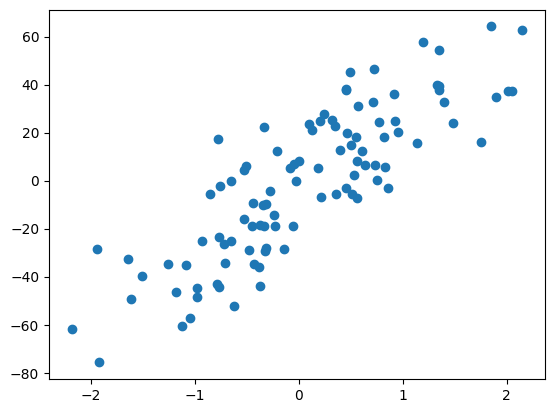

In [41]:
plt.scatter(x,y)

In [42]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x,y)
print(lr.coef_)
print(lr.intercept_)


[27.82809103]
-2.29474455867698


In [43]:
np.mean(cross_val_score(lr,x,y,scoring='r2',cv=10))

np.float64(0.6375011587464419)

In [44]:
class GDRegressor:
    def __init__(self,learning_rate,epochs):
        self.m=100
        self.b=-120
        self.learning_rate=learning_rate
        self.epochs=epochs

    def fit(self,x,y):
        #calculate the b using gdregressor
        for i in range(self.epochs):
            loss_slope_b=-2 *np.sum(y-self.m*x.ravel()-self.b)
            loss_slope_m=-2 *np.sum((y-self.m*x.ravel()-self.b)*x.ravel())

            self.b=self.b-(self.learning_rate*loss_slope_b)
            self.m=self.m-(self.learning_rate*loss_slope_m)
            print(self.m,self.b)


gd=GDRegressor(0.001,100)
gd.fit(x,y)

88.7901778060777 -97.30202349511147
79.26989400677363 -79.01269499728718
71.19603915550572 -64.2700212110887
64.357826042914 -52.381567622457695
58.573134285938856 -42.79092431395032
53.685100591058074 -35.05083591632167
49.55898969983806 -28.80166573902754
46.07935938462746 -23.754130522644466
43.14751810732243 -19.6754551237646
40.679264258689464 -16.378266564607884
38.602889878179504 -13.711682863685132
36.85742837440565 -11.55416078082497
35.391124246007365 -9.807753543980294
34.160102562818395 -8.393499154751025
33.12721658147269 -7.2477154903755485
32.2610530264308 -6.3190229237706514
31.53507604240516 -5.5659507997754325
30.926892458014258 -4.955012616245335
30.417622682493505 -4.459157586120731
29.991363212652477 -4.056524538225423
29.63472830753753 -3.729438759192164
29.33645986404345 -3.463604113085621
29.087095882238803 -3.2474521798712006
28.87868913818444 -3.0716176933750234
28.70456878480573 -2.9285156053345553
28.559138582490913 -2.8119999517848964
28.437706327772243 -2.

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [46]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=13)

In [47]:
lr=LinearRegression()


In [48]:
lr.fit(x_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[28.67684216]
-2.0886997661340985


In [49]:
y_pred=lr.predict(x_test)
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.71337703667083

In [59]:
class GDRegressor:
    def __init__(self,learning_rate,epochs):
        self.m=100
        self.b=-120
        self.learning_rate=learning_rate
        self.epochs=epochs

    def fit(self,x,y):
        #calculate the b using gdregressor
        for i in range(self.epochs):
            loss_slope_b=-2 *np.sum(y-self.m*x.ravel()-self.b)
            loss_slope_m=-2 *np.sum((y-self.m*x.ravel()-self.b)*x.ravel())

            self.b=self.b-(self.learning_rate*loss_slope_b)
            self.m=self.m-(self.learning_rate*loss_slope_m)
            print(self.m,self.b)

    def predict(self,x):
        return self.m*x.ravel()+self.b
gd=GDRegressor(0.001,50)
gd.fit(x_train,y_train)

89.75696942111873 -100.51323048144818
81.00721256756053 -84.2335230795076
73.52984526143626 -70.63474695241547
67.1371068835468 -59.2768752790902
61.66933046179499 -49.7919202318714
56.990685184884214 -41.87216214558794
52.98557155366008 -35.260299086568324
49.55556811593215 -29.74120387553719
46.61684451354982 -25.135026569519834
44.09796887035851 -21.291423069454535
41.93804875946692 -18.08472624014588
40.08515443852955 -15.40990583633972
38.494981010465004 -13.179188568427653
37.12971288801812 -11.319230605281541
35.95705961054797 -9.768752362957384
34.94943684591153 -8.476560121683951
34.08327044861552 -7.3998913145842575
33.3384048547816 -6.503030629286669
32.69759997362405 -5.75615268397472
32.14610316719448 -5.134354255487431
31.6712849651048 -4.616845077400356
31.262328897763794 -4.1862712819939984
30.90996730003379 -3.828149791915101
30.60625617899579 -3.5303955093472394
30.34438328999145 -3.28292611498502
30.118504454036238 -3.0773317701217677
29.92360390215555 -2.90659909147

In [60]:
y_pred=gd.predict(x_test)


In [61]:
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.7129234154065953